langgraph的中断机制，是构建人工介入（Human-In-The-Loop）HITL工作流的重要能力

Agent执行到某个节点，主动暂停，把情况交给人来判断，人在处理完成之后，再从暂停的位置重新执行。

例如：AI自动化系统：
1. 人工审批
2. 人工确认：AI准备删除文件，发送邮件，或者执行数据库修改前，先询问用户
3. 人工修改
4. 人工补充信息：Agent缺少必要参数，暂停等待人工补充

中断核心概念：
interrupt(value)：触发中断，先调用方传递待处理信息
Command(resume=xxx)：恢复执行，并将外部数据传回中断位置
checkpointer：保存图的状态，支持之后恢复


这里的中断让图的状态暂停执行，并且通过持久化状态，支持之后恢复。



In [ ]:
from IPython import display

转账人工审批案例：
业务需求：
1. Node A 生成一笔待处理的转账申请。
2. Node B 暂停，等待人工审批。
3. 人工返回批准或拒绝。
4. Node C 根据审批结果执行对应操作。
5. 图保存执行状态，允许之后恢复。



interrupt() 的返回值来自恢复执行时 Command(resume=...) 里传入的值

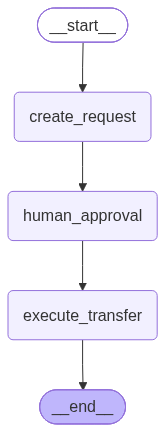

创建转账申请：500 元
进入审批节点
第一次执行结果： {'amount': 500, 'approved': None, 'result': '等待审批', '__interrupt__': [Interrupt(value={'type': 'approval', 'message': '是否批准这笔转账？', 'amount': 500}, id='77c52a17e5dcad604112e662a722eab8', response_schema=None)]}
进入审批节点
人工审核结果： True
转账成功：500 元
{'amount': 500, 'approved': True, 'result': '转账成功'}


In [8]:
from typing import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt, Command


# 1. 定义状态
class State(TypedDict):
    amount: int
    approved: bool | None
    result: str


# 2. Node A：生成申请
def create_request(state: State):
    print(f"创建转账申请：{state['amount']} 元")

    return {
        "approved": None,
        "result": "等待审批"
    }


# 3. Node B：人工审批
def human_approval(state: State):
    print("进入审批节点")

    # 执行到这里时，图会暂停
    # interrupt() 的返回值来自恢复执行时 Command(resume=...) 里传入的值
    decision = interrupt({
        "type": "approval",
        "message": "是否批准这笔转账？",
        "amount": state["amount"]
    })

    # 恢复后，decision 就是人工传入的值
    print("人工审核结果：",decision)
    return {
        "approved": decision
    }


# 4. Node C：执行审批结果
def execute_transfer(state: State):
    if state["approved"]:
        print(f"转账成功：{state['amount']} 元")
        return {"result": "转账成功"}

    print("转账被拒绝")
    return {"result": "转账被拒绝"}


# 5. 构建图
builder = StateGraph(State)

builder.add_node("create_request", create_request)
builder.add_node("human_approval", human_approval)
builder.add_node("execute_transfer", execute_transfer)

builder.add_edge(START, "create_request")
builder.add_edge("create_request", "human_approval")
builder.add_edge("human_approval", "execute_transfer")
builder.add_edge("execute_transfer", END)

# 中断需要 Checkpointer
checkpointer = InMemorySaver()

graph = builder.compile(checkpointer=checkpointer)


# 6. 指定线程 ID
config = {
    "configurable": {
        "thread_id": "transfer-001"
    }
}


# 7. 第一次执行

display(graph)

result = graph.invoke(
    {
        "amount": 500,
        "approved": None,
        "result": ""
    },
    config=config
)

print("第一次执行结果：", result)

print("=" * 60)

# 拒绝审批 实际生产环境不能允许任意客户端直接提交 True 就获得审批权限，必须在后端校验审批人身份、审批权限、业务单据状态等信息。
# 中断必须使用相同的thread_id
result2 = graph.invoke(
    Command(resume=True),
    config=config
)


print(result2)